# 1. Load in Data and Initialise Spark

In [2]:
# import findspark
import findspark
# initialize findspark with spark directory
findspark.init()
# import pyspark
import pyspark
# create spark contextp
sc = pyspark.SparkContext()
# create spark session
spark = pyspark.sql.SparkSession(sc)

In [3]:
spark

In [4]:
# import required packages
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# import pyspark functionalities
from pyspark.sql.types import NumericType, FloatType
from pyspark.ml import Pipeline
from pyspark.sql.window import Window
from pyspark.sql import functions as F
from pyspark.ml.stat import Correlation
from pyspark.ml.feature import VectorAssembler, StandardScaler, StringIndexer, OneHotEncoder, CountVectorizer, VectorSizeHint
from pyspark.ml.classification import LogisticRegression, RandomForestClassifier, GBTClassifier
from pyspark.ml.evaluation import BinaryClassificationEvaluator
from pyspark.ml.linalg import VectorUDT, Vectors
from pyspark.ml.functions import vector_to_array

# turn of warnings
import warnings
warnings.filterwarnings("ignore")

In [5]:
basetable = spark.read.parquet("../Cleaned_data/biweekly_basetable_w_sentiment_5.parquet")
basetable.show(5)

+--------+---------------+--------------+------+--------------------+---------+------------+----------+-----------+------------+-----------+----------+------------------+--------------------+-----------------------+--------------------+--------------------+--------------------+--------------------+--------------------+------------+------------------+----------------+------------------+------------------+--------------------+---------+--------------------+-------------------+-------+---------+---------------------+------------------------+-----------------------+--------+-------------------+-------------------------+-------------+--------------------+---------------------+---------------------+----------------------+--------------+------------------------+-------------------------+------------------------------+---------------------------+----------------------------------+---------------------------------+--------------------+------------------+------------------+---------+------------

# 2. Model Evaluation & Explenation

## 2.1 Time based split

In [6]:
# Determine the the cutoff biweekly index
max_index = basetable.agg(F.max("biweekly_index")).collect()[0][0]
cutoff_index = int(max_index * 0.67)

train_df = basetable.filter(F.col("biweekly_index") <= cutoff_index)
test_df  = basetable.filter(F.col("biweekly_index") > cutoff_index)

## 2.2 Imputing Missing Values 

(in previous notebooks, most null values are already handles)

In [7]:
train_df = train_df.filter(F.col("prev_period_return").isNotNull())
train_df = train_df.fillna(0)

In [8]:
test_df = test_df.fillna(0)

## 2.3 Feature selection

In [9]:
label_col = "financing_next_period"
cat_cols = ["industry", "maturity", "locations"]
id_cols =  ["ticker", "biweekly_index","biweekly_period", "longname", "benchmark", "period_start", "period_end"]
vec_cols = ["avg_finbert_vec_comp","finbert_embedding_ft"]

exclude_cols = set(id_cols + [label_col])

feature_columns = [c for c in train_df.columns if c not in exclude_cols]
numeric_feature_cols = [col for col in feature_columns if col not in cat_cols]
real_numeric_feature_cols = [col for col in numeric_feature_cols if col not in vec_cols]

non_relevant_num_cols = [
    "period_open", "period_close", "period_high", "period_low", # period cols (avg_close, period_return)
    "avg_intraday_range", "max_intraday_range", # return_volatility
    "total_volume", "max_daily_volume", "avg_volume_up_days", "avg_volume_down_days", # avg_daily_volume, volume_volatility
    "prev_avg_daily_volume", # prev_volume_volatility
    "total_words_ft", # article_count_ft
    "total_words_tijd", # article_count_tijd
    "median_roberta_ca", "min_roberta_ca", "max_roberta_ca", # simplify sentiment signals
    "min_ollama_comp", "max_ollama_comp", "avg_num_words_title_comp", "avg_num_words_content_comp" # simplify sentiment signals 
]
relevant_num_cols = [c for c in real_numeric_feature_cols if c not in non_relevant_num_cols]

sent_cols = [c for c in basetable.columns if c.endswith(("_ca", "_comp", "_ft", "_tijd")) and c not in non_relevant_num_cols]

In [10]:
sent_cols

['n_comments_ca',
 'avg_vader_ca',
 'std_vader_ca',
 'avg_roberta_ca',
 'n_artices_comp',
 'avg_polarity_title_comp',
 'avg_polarity_content_comp',
 'avg_subjectivity_title_comp',
 'avg_subjectivity_content_comp',
 'avg_ollama_comp',
 'std_ollama_comp',
 'avg_FPI_comp',
 'std_FPI_comp',
 'avg_finbert_vec_comp',
 'accum_FPI_comp',
 'std_avg_FPI_last3_comp',
 'prev_std_FPI_comp',
 'prev_avg_FPI_comp',
 'article_count_ft',
 'avg_words_ft',
 'polarity_ft',
 'subjectivity_ft',
 'ollama_sentiment_ft',
 'finbert_embedding_ft',
 'article_count_tijd',
 'avg_words_tijd',
 'polarity_tijd',
 'subjectivity_tijd',
 'ollama_sentiment_tijd']

## 2.3.1 Scaling

First Scaling the ticker specific values (these can be significantly different from ticker to ticker, so these should be standardised per ticker)

In [11]:
scale_cols = [
    "period_open","period_close","period_high","period_low","avg_close",
    "price_volatility","avg_intraday_range","max_intraday_range",
    "total_volume","avg_daily_volume","max_daily_volume","volume_volatility",
    "avg_volume_up_days","avg_volume_down_days",
    "avg_gap_size","max_gap",
    "avg_prChg",
    "prev_price_volatility","prev_avg_daily_volume","prev_volume_volatility"
]
scale_cols = [c for c in scale_cols if c not in non_relevant_num_cols]
no_scale_cols = [c for c in relevant_num_cols if c not in scale_cols and c not in sent_cols]

In [12]:
# Fit stats op TRAIN
agg_exprs = []
for c in scale_cols:
    agg_exprs += [
        F.avg(F.col(c)).alias(f"{c}__mean"),
        F.stddev_samp(F.col(c)).alias(f"{c}__std"),
    ]

stats_df = train_df.groupBy("ticker").agg(*agg_exprs)


def apply_per_ticker_zscore(df, stats_df, scale_cols):
    df = df.join(stats_df, on="ticker", how="left")
    zcols = []

    for c in scale_cols:
        mu = F.col(f"{c}__mean")
        sd = F.col(f"{c}__std")
        z  = f"{c}__z"

        df = df.withColumn(
            z,
            F.when(sd.isNull() | (sd == 0), F.lit(0.0))
             .otherwise((F.col(c) - mu) / sd)
        )
        zcols.append(z)

    # drop stats cols
    drop_cols = [f"{c}__mean" for c in scale_cols] + [f"{c}__std" for c in scale_cols]
    df = df.drop(*drop_cols)

    return df, zcols


train_s, zcols = apply_per_ticker_zscore(train_df, stats_df, scale_cols)
test_s,  _     = apply_per_ticker_zscore(test_df,  stats_df, scale_cols)

Now Scaling of the Sentiment features

In [13]:
sent_VA = VectorAssembler(
    inputCols=sent_cols,
    outputCol="sent_vec",
    handleInvalid="keep"
)

In [14]:
sent_scaler = StandardScaler(
    inputCol="sent_vec",
    outputCol="sent_scaled",
    withStd=True,
    withMean=False   # keep sparse-friendly; sentiment is dense but this is safe
)

## 2.3.2 Encode Categorical Features

In [15]:
# Indexers
industry_indexer = StringIndexer(inputCol="industry", outputCol="industry_idx", handleInvalid="keep")
maturity_indexer = StringIndexer(inputCol="maturity", outputCol="maturity_idx", handleInvalid="keep")

# One-hot encoder
ENC = OneHotEncoder(
    inputCols=["industry_idx", "maturity_idx"],
    outputCols=["industry_ohe", "maturity_ohe"],
    handleInvalid="keep"
)

In [16]:
CV = CountVectorizer(
    inputCol="locations",
    outputCol="locations_vec",
    binary=True,     # True = presence/absence; set False if counts matter
    minDF=2          # ignore super-rare locations (tune)
)

## 2.3.3 Vector hints

In [17]:
vector_cols = [
    "avg_finbert_vec_comp",
    "finbert_embedding_ft"
]

hints = [
    VectorSizeHint(
        inputCol=c,
        size=768,
        handleInvalid="error"   # or "skip"
    )
    for c in vector_cols
]

# 2.3.4 Weights

In [18]:
counts = (
    train_df
    .groupBy(label_col)
    .count()
    .withColumnRenamed("count", "n")
)

total = counts.agg(F.sum("n")).collect()[0][0]

weights = (
    counts
    .withColumn("weight", total / (2 * F.col("n")))
)

weights.show()
def apply_weights(df):
    return df.join(weights, on="financing_next_period", how="left")

train_w = apply_weights(train_s)
test_w  = apply_weights(test_s)

+---------------------+---+------------------+
|financing_next_period|  n|            weight|
+---------------------+---+------------------+
|                    1| 16|           9.96875|
|                    0|303|0.5264026402640264|
+---------------------+---+------------------+



In [19]:
train = apply_weights(train_df)
test = apply_weights(test_df)

## 2.3.5 Vector Assembling

In [20]:
VA = VectorAssembler(
    inputCols=real_numeric_feature_cols,
    outputCol="features"
)

## 2.3.6 Feature Selection

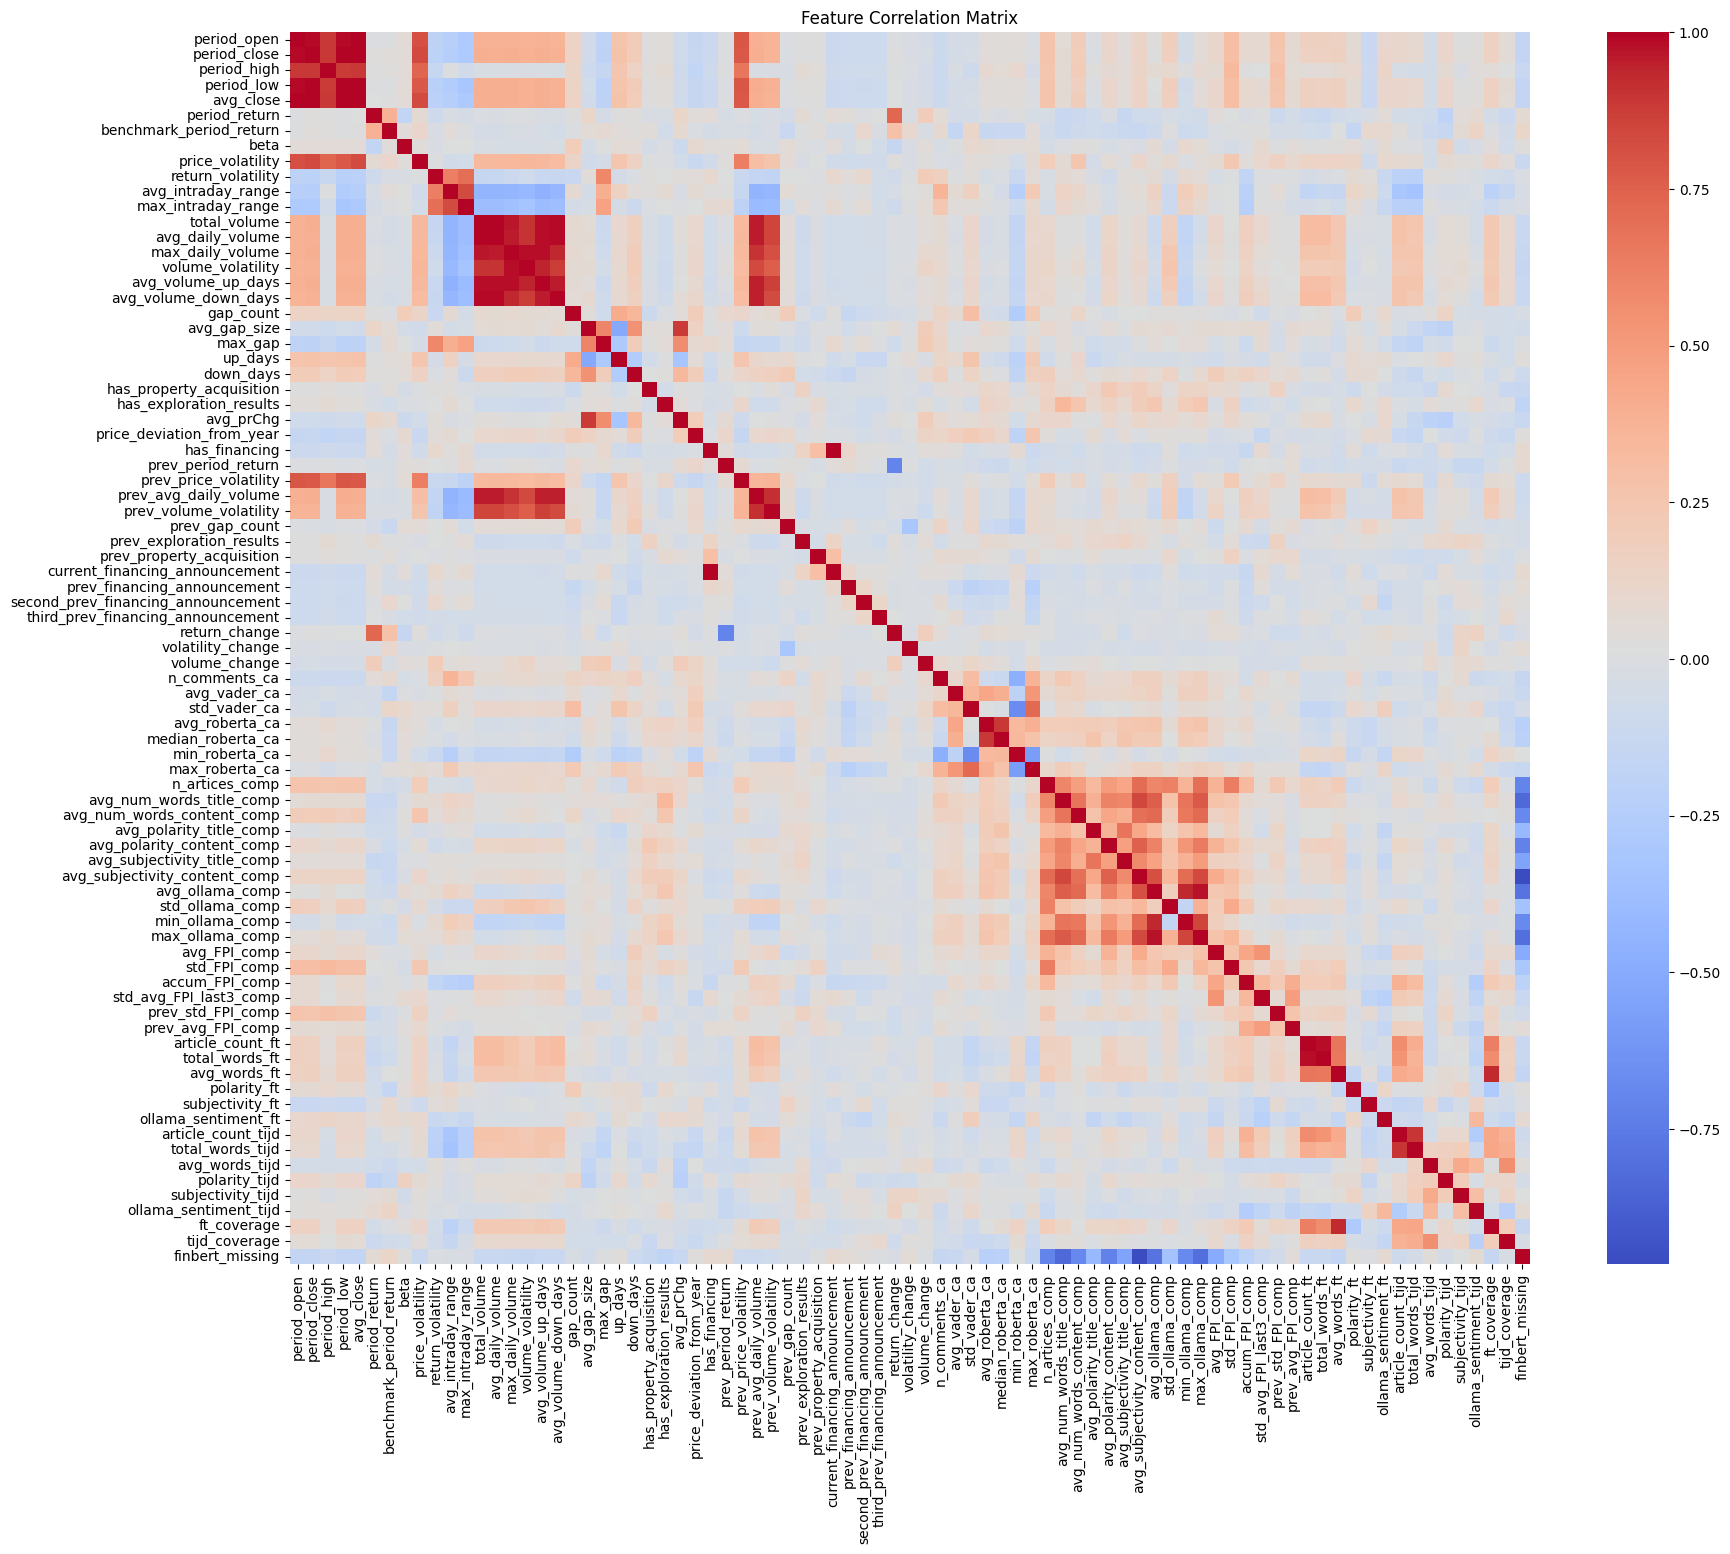

In [21]:
# assemble the features into a vector
df_vector = VA.transform(train_df).select("features")

# calculate the correlation matrix
correlation_matrix = Correlation.corr(df_vector, "features").head()[0]

# convert the DenseMatrix to a NumPy array
corr_array = np.array(correlation_matrix.toArray())

# create a Pandas DataFrame from the correlation array for visualization
corr_df = pd.DataFrame(corr_array, columns=real_numeric_feature_cols, index=real_numeric_feature_cols)

# plot the heatmap
plt.figure(figsize=(20, 16))
sns.heatmap(corr_df, annot=False, cmap="coolwarm", fmt=".2f")
plt.title("Feature Correlation Matrix")
plt.show()

As we can see there are multiple blocks clearly visible in the matrrix. This shows high correlation -> reduundancy within blocks but high complementarity across blocks. Next step would be to compress within blocks (NOT delete blocks)

In [22]:
non_relevant_num_cols = [
    "period_open", "period_close", "period_high", "period_low", # period cols (avg_close, period_return)
    "avg_intraday_range", "max_intraday_range", # return_volatility
    "total_volume", "max_daily_volume", "avg_volume_up_days", "avg_volume_down_days", # avg_daily_volume, volume_volatility
    "prev_avg_daily_volume", # prev_volume_volatility
    "total_words_ft", # article_count_ft
    "total_words_tijd", # article_count_tijd
    "median_roberta_ca", "min_roberta_ca", "max_roberta_ca", # simplify sentiment signals
    "min_ollama_comp", "max_ollama_comp", "avg_num_words_title_comp", "avg_num_words_content_comp" # simplify sentiment signals 
]
relevant_num_cols = [c for c in real_numeric_feature_cols if c not in non_relevant_num_cols]

In [23]:
VA = VectorAssembler(
    inputCols=relevant_num_cols,
    outputCol="features"
)

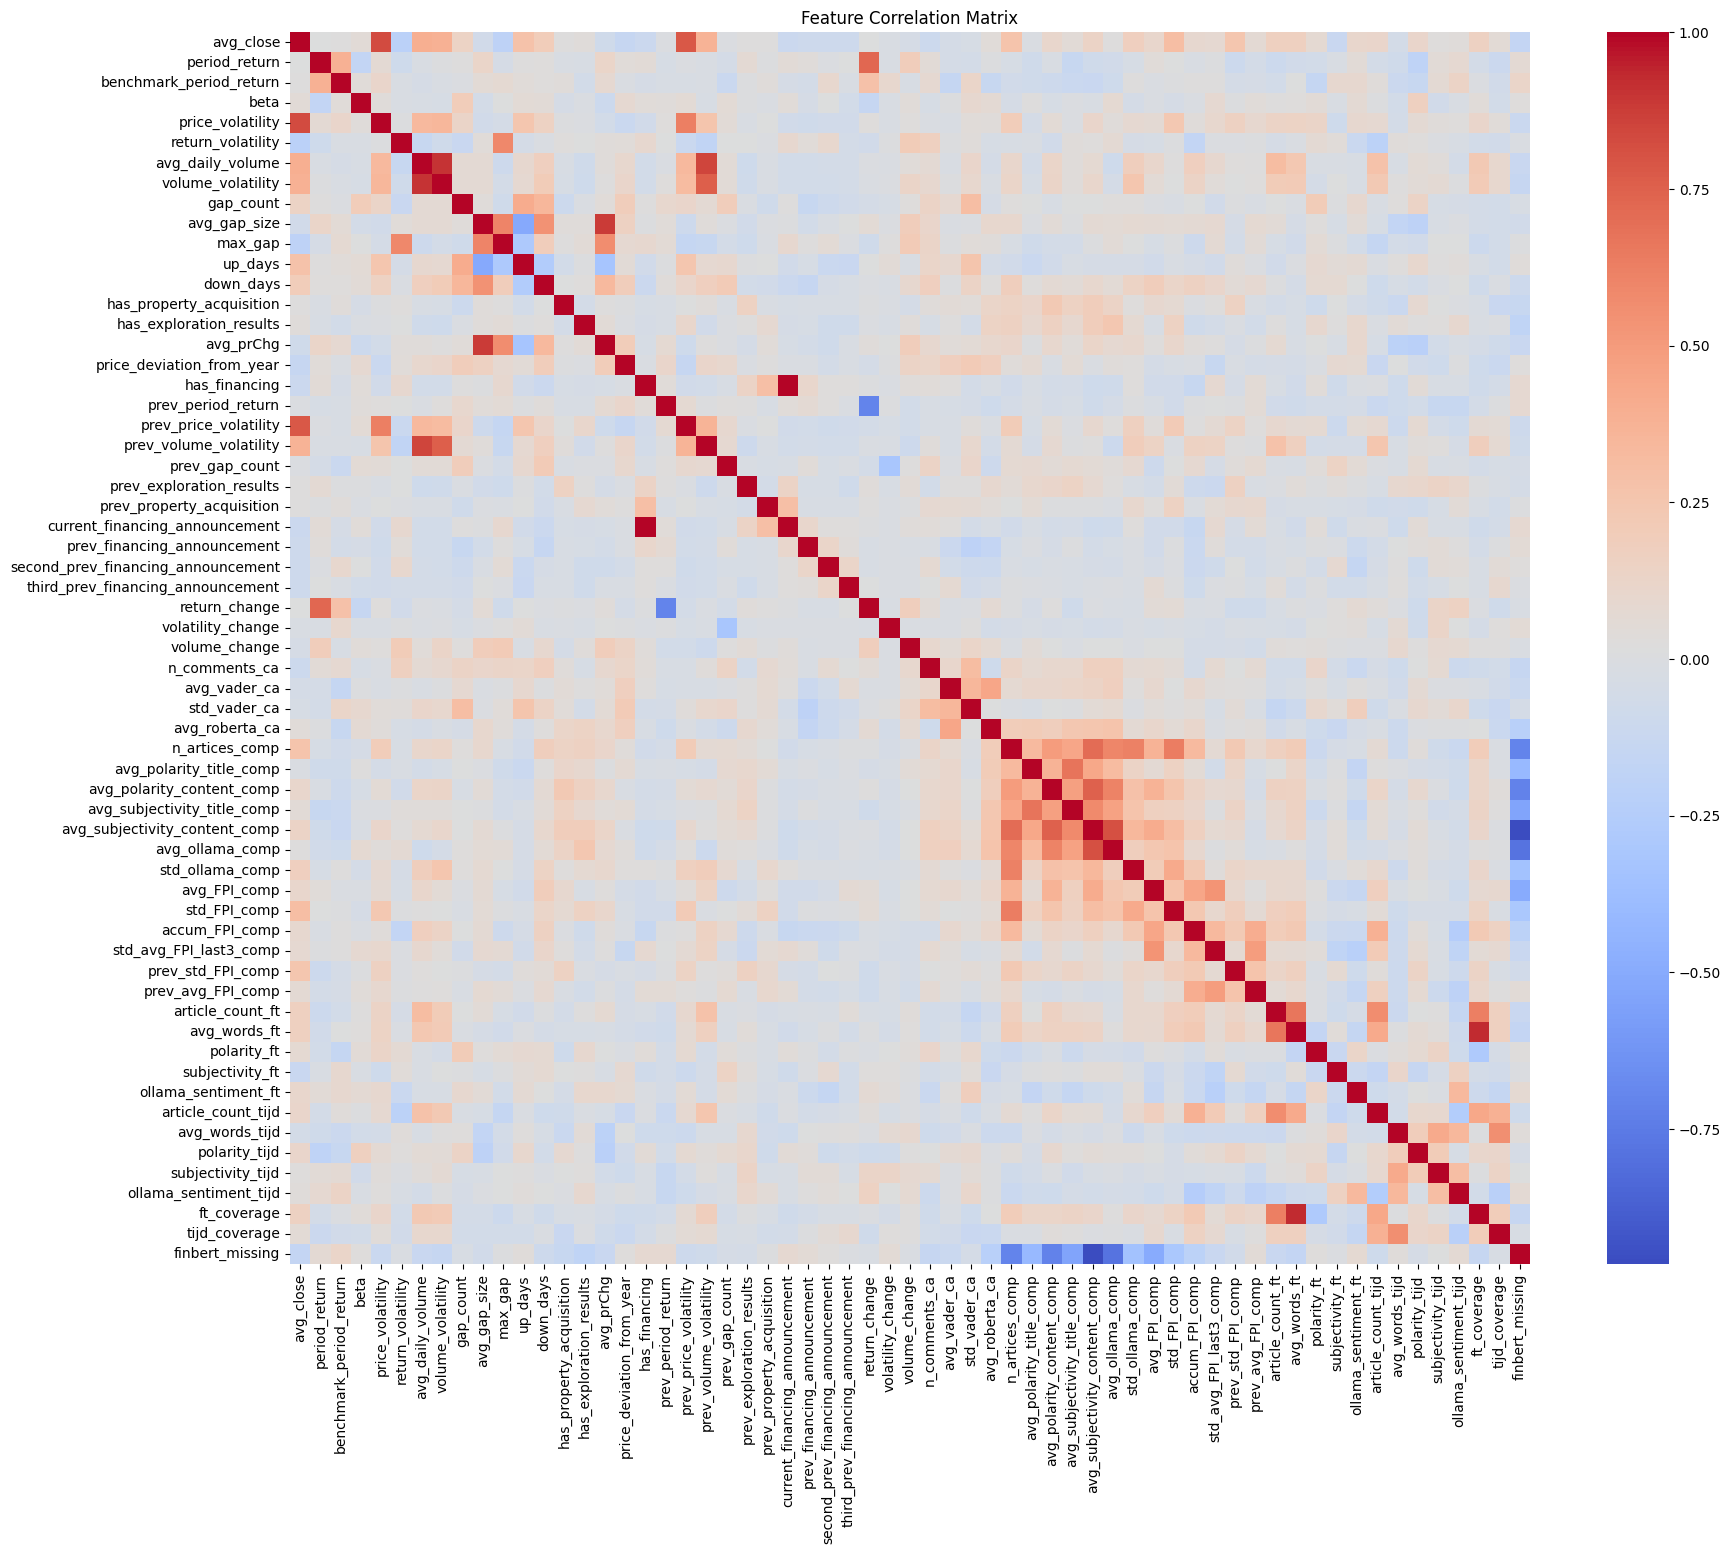

In [24]:
# assemble the features into a vector
df_vector = VA.transform(train_df).select("features")

# calculate the correlation matrix
correlation_matrix = Correlation.corr(df_vector, "features").head()[0]

# convert the DenseMatrix to a NumPy array
corr_array = np.array(correlation_matrix.toArray())

# create a Pandas DataFrame from the correlation array for visualization
corr_df = pd.DataFrame(corr_array, columns=relevant_num_cols, index=relevant_num_cols)

# plot the heatmap
plt.figure(figsize=(20, 16))
sns.heatmap(corr_df, annot=False, cmap="coolwarm", fmt=".2f")
plt.title("Feature Correlation Matrix")
plt.show()

## 2.3.7 Trying LR with reduced variables set

In [25]:
VA_final = VectorAssembler(
    inputCols=sent_cols + [f"{c}_ohe" for c in ["industry", "maturity"]] + ["locations_vec"] + zcols + no_scale_cols,
    outputCol="features"
)

In [26]:
# define linear regression model
LR = LogisticRegression(featuresCol="features", labelCol=label_col, elasticNetParam=0.8, regParam=0.001, weightCol="weight")

# fit model on train
lr_pipeline = Pipeline(stages=[
    industry_indexer,
    maturity_indexer,
    ENC,
    CV,
    *hints,
    sent_VA,
    sent_scaler,
    VA_final,
    LR
])

# Model training
lr_model = lr_pipeline.fit(train_w)

In [27]:
def calculate_classification_metrics(predictions, label_col, prediction_col):
    # calculate true positives, true negatives, false positives, false negatives
    tp = predictions.filter((F.col(label_col) == 1) & (F.col(prediction_col) == 1)).count()
    tn = predictions.filter((F.col(label_col) == 0) & (F.col(prediction_col) == 0)).count()
    fp = predictions.filter((F.col(label_col) == 0) & (F.col(prediction_col) == 1)).count()
    fn = predictions.filter((F.col(label_col) == 1) & (F.col(prediction_col) == 0)).count()

    # calculate accuracy
    accuracy = (tp + tn) / (tp + tn + fp + fn)
    
    # calculate precision
    precision = tp / (tp + fp) if (tp + fp) != 0 else 0  
    
    # calculate recall
    recall = tp / (tp + fn) if (tp + fn) != 0 else 0.0  
    
    # calculate F1 measure
    f1_measure = 2 * (precision * recall) / (precision + recall) if (precision + recall) != 0 else 0.0  

    # print the metrics
    print(f"Accuracy: {accuracy}")
    print(f"Precision: {precision}")
    print(f"Recall: {recall}")
    print(f"F1 measure: {f1_measure}")
    
    return accuracy, precision, recall, f1_measure

In [28]:
lr_predictions = lr_model.transform(test_w)

In [29]:
lr_accuracy, lr_precision, lr_recall, lr_f1_measure = calculate_classification_metrics(lr_predictions, 'financing_next_period', 'prediction')

Accuracy: 0.748
Precision: 0.12903225806451613
Recall: 0.47058823529411764
F1 measure: 0.20253164556962025


Without weights:

- Accuracy: 0.808
- Precision: 0.13953488372093023
- Recall: 0.35294117647058826
- F1 measure: 0.2

With weights:

- Accuracy: 0.748
- Precision: 0.12903225806451613
- Recall: 0.47058823529411764
- F1 measure: 0.20253164556962025


# 3. Variable Importance Using GBT

## 3.1 GBT model

In [30]:
# define boosting model
GBT = GBTClassifier(
    featuresCol="features", 
    labelCol="financing_next_period",
    maxDepth=3,                
    maxIter=80,               
    stepSize=0.05,              
    subsamplingRate=0.8,       
    minInstancesPerNode=20,     
    seed=42,
    weightCol="weight"
)

# fit model on train
gbt_pipeline = Pipeline(stages=[
    industry_indexer,
    maturity_indexer,
    ENC,
    CV,
    *hints,
    sent_VA,
    sent_scaler,
    VA_final,
    GBT
])

# model training
gbt_model = gbt_pipeline.fit(train_w)

In [31]:
gbt_predictions = gbt_model.transform(test_w)

In [32]:
gbt_accuracy, gbt_precision, gbt_recall, gbt_f1_measure = calculate_classification_metrics(gbt_predictions, 'financing_next_period', 'prediction')

Accuracy: 0.872
Precision: 0.14285714285714285
Recall: 0.17647058823529413
F1 measure: 0.15789473684210528


In [33]:
# get AUC
evaluator = BinaryClassificationEvaluator(labelCol="financing_next_period", 
                                          rawPredictionCol="probability", 
                                          metricName="areaUnderROC")
gbt_AUC = evaluator.evaluate(gbt_predictions)
print(f"AUC: {gbt_AUC:.4f}")

AUC: 0.5890


With Threshold Lowered

In [34]:
def calculate_classification_metrics_thresh(predictions, label_col, threshold=0.2):
    preds = predictions.withColumn(
        "pred_label",
        (vector_to_array("probability")[1] >= F.lit(threshold)).cast("int")
    )

    tp = preds.filter((F.col(label_col) == 1) & (F.col("pred_label") == 1)).count()
    tn = preds.filter((F.col(label_col) == 0) & (F.col("pred_label") == 0)).count()
    fp = preds.filter((F.col(label_col) == 0) & (F.col("pred_label") == 1)).count()
    fn = preds.filter((F.col(label_col) == 1) & (F.col("pred_label") == 0)).count()

    accuracy  = (tp + tn) / (tp + tn + fp + fn) if (tp + tn + fp + fn) else 0
    precision = tp / (tp + fp) if (tp + fp) else 0
    recall    = tp / (tp + fn) if (tp + fn) else 0
    f1        = 2 * precision * recall / (precision + recall) if (precision + recall) else 0

    print(f"Threshold: {threshold}")
    print(f"TP={tp}, FP={fp}, FN={fn}, TN={tn}")
    print(f"Accuracy:  {accuracy:.3f}")
    print(f"Precision: {precision:.3f}")
    print(f"Recall:    {recall:.3f}")
    print(f"F1:        {f1:.3f}")

    return accuracy, precision, recall, f1

In [35]:
gbt_accuracy, gbt_precision, gbt_recall, gbt_f1 = calculate_classification_metrics_thresh(
    gbt_predictions,
    label_col="financing_next_period",
    threshold=0.2
)

Threshold: 0.2
TP=7, FP=58, FN=10, TN=175
Accuracy:  0.728
Precision: 0.108
Recall:    0.412
F1:        0.171


In [36]:
thr = 0.2

gbt_predictions_adj = (
    gbt_predictions
    .withColumn("p1", vector_to_array("probability")[1])
    .withColumn("pred_label_thr", (F.col("p1") >= F.lit(thr)).cast("int"))
)

gbt_predictions_adj.select(
    "ticker", "biweekly_period", "financing_next_period",
    "p1", "prediction", "pred_label_thr"
).show(20, truncate=False)

+------+---------------+---------------------+--------------------+----------+--------------+
|ticker|biweekly_period|financing_next_period|p1                  |prediction|pred_label_thr|
+------+---------------+---------------------+--------------------+----------+--------------+
|ARG.TO|P31            |0                    |0.02982824678081608 |0.0       |0             |
|ARG.TO|P32            |0                    |0.053535751312299706|0.0       |0             |
|ARG.TO|P33            |0                    |0.020916068179217207|0.0       |0             |
|ARG.TO|P34            |0                    |0.01433831093996385 |0.0       |0             |
|ARG.TO|P35            |0                    |0.048302613537138495|0.0       |0             |
|ARG.TO|P36            |0                    |0.4342376390608177  |0.0       |1             |
|ARG.TO|P37            |0                    |0.014826169055101035|0.0       |0             |
|ARG.TO|P38            |0                    |0.086434495834

In [37]:
gbt_adj_AUC = evaluator.evaluate(gbt_predictions_adj)
print(f"AUC: {gbt_AUC:.4f}")

AUC: 0.5890


With Threshold = Default

- Accuracy: 0.872
- Precision: 0.14285714285714285
- Recall: 0.17647058823529413
- F1 measure: 0.15789473684210528
 

With Threshold = Default

- Threshold: 0.2
- TP=7, FP=58, FN=10, TN=175
- Accuracy:  0.728
- Precision: 0.108
- Recall:    0.412
- F1:        0.171



## 3.2 Confusion matrix

Default Threshold

In [38]:
# import confusion matrix
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

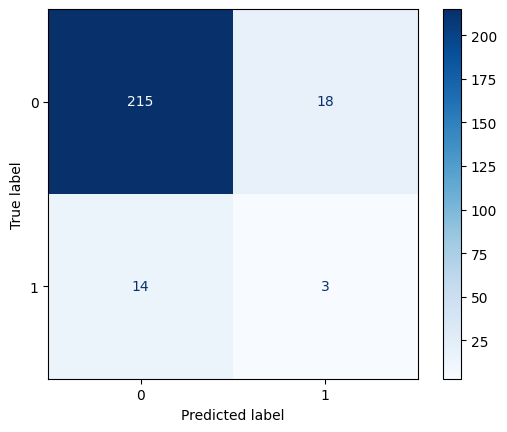

In [39]:
# get predictions and labels
preds_and_labels = gbt_predictions.select(['prediction','financing_next_period']) \
                                  .withColumn('label', F.col('financing_next_period').cast(FloatType())) \
                                  .orderBy('prediction') \
                                  .toPandas()

# get confusion matrix
cm = confusion_matrix(preds_and_labels["label"], preds_and_labels["prediction"], labels=[0, 1])

# get confusion matrix figure
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=[0, 1])

# plot figure
disp.plot(cmap="Blues")
plt.show()

Adjusted Threshold (0.2)

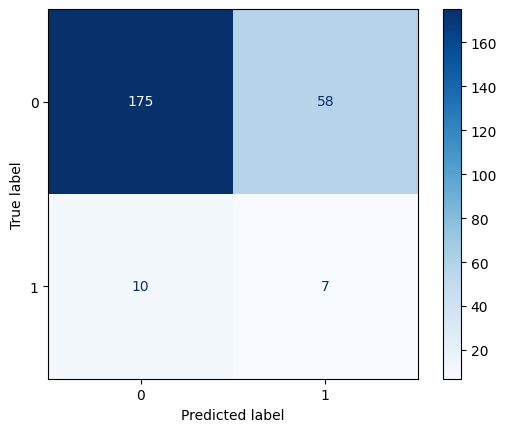

In [40]:
# get predictions and labels
preds_and_labels = gbt_predictions_adj.select(['pred_label_thr','financing_next_period']) \
                                  .withColumn('label', F.col('financing_next_period').cast(FloatType())) \
                                  .orderBy('pred_label_thr') \
                                  .toPandas()

# get confusion matrix
cm = confusion_matrix(preds_and_labels["label"], preds_and_labels["pred_label_thr"], labels=[0, 1])

# get confusion matrix figure
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=[0, 1])

# plot figure
disp.plot(cmap="Blues")
plt.show()

## 3.3 ROC-Curve

Default threshold

In [41]:
# import required packages
from sklearn.metrics import roc_curve

# get array of labels
l = np.squeeze(np.array(gbt_predictions.select("financing_next_period").collect()))

# get array of predicted probabilities
p = np.squeeze(np.array(gbt_predictions.select("probability").collect()))[:, 1]

# get fpr and tpr
fpr, tpr, t = roc_curve(l, p)

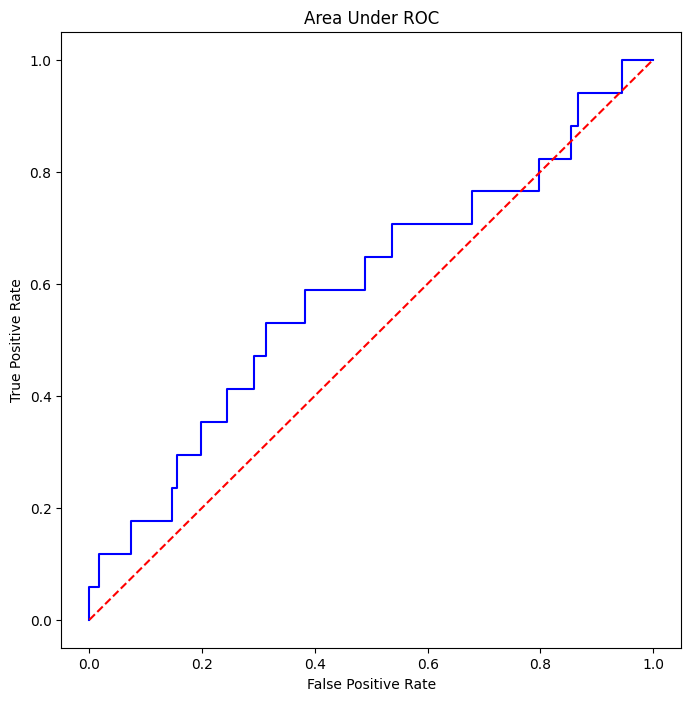

In [42]:
# plot ROC curve
plt.figure(figsize=(8, 8))
plt.plot(fpr, tpr, color="blue")
# dashed line for random classifier
plt.plot([0, 1], [0, 1], "--", color="red")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Area Under ROC")
plt.show()

## 3.4 Lift curve

In [43]:
# get labels and predictions
l_p = pd.DataFrame({"label": l, "prediction": p})

# sort by probability
l_p = l_p.sort_values(by="prediction", ascending=False)

# check
l_p.head(50)

,label,prediction
113,1,0.946887
214,0,0.881605
59,0,0.874929
213,0,0.830393
116,0,0.791039
34,1,0.750851
218,0,0.729418
216,0,0.717496
111,0,0.707711
128,0,0.691977


In [44]:
# get average response rate
avg_response_rate = np.mean(l_p["label"])

# define empty container for lift scores
lift_scores = []

# get chunk size 
chunk_size = int(len(l_p) / 10)

# loop through 10 chunks (NOTE: we only have 48 obs in test set!)
for i in range(10):
  # get chunk of data
  chunk = l_p.iloc[i*chunk_size:(i+1)*chunk_size]
  # get model response rate
  model_response_rate = np.mean(chunk["label"])
  # get lift
  lift_score = model_response_rate / avg_response_rate
  # add to container
  lift_scores.append(lift_score)

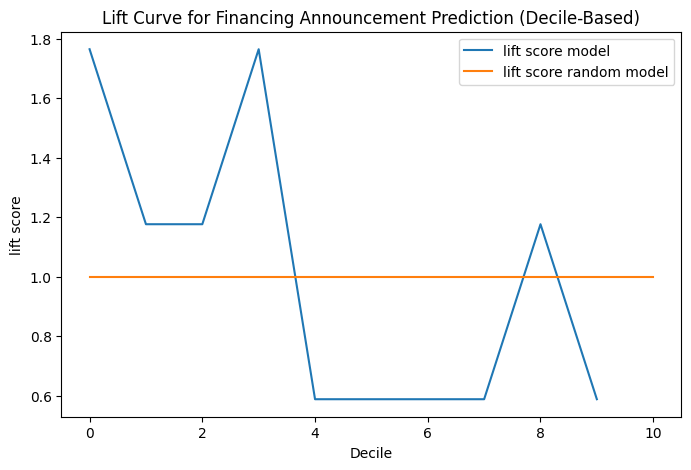

In [45]:
# plot lift scores
plt.figure(figsize=(8, 5))
plt.plot(range(10), lift_scores, label="lift score model")
plt.plot([0, 10], [1, 1], "-", label="lift score random model")
plt.xlabel("Decile")
plt.ylabel("lift score")
plt.title("Lift Curve for Financing Announcement Prediction (Decile-Based)")
plt.legend(loc="upper right")
plt.show()

The lift curve demonstrates that the model effectively concentrates financing announcements in the highest-ranked deciles. In the top decile, the model achieves a lift of approximately 1.75, indicating a 75% improvement over random selection. Beyond the first three deciles, lift drops below one, suggesting that most predictive signal is captured early. This behavior is consistent with rare-event prediction settings and supports the model’s use as a screening and early-warning tool rather than a global classifier.

# 3.5 Model explanation

### 3.5.1 Feature importance

In [46]:
feature_columns = VA_final.getInputCols()
feature_columns

['n_comments_ca',
 'avg_vader_ca',
 'std_vader_ca',
 'avg_roberta_ca',
 'n_artices_comp',
 'avg_polarity_title_comp',
 'avg_polarity_content_comp',
 'avg_subjectivity_title_comp',
 'avg_subjectivity_content_comp',
 'avg_ollama_comp',
 'std_ollama_comp',
 'avg_FPI_comp',
 'std_FPI_comp',
 'avg_finbert_vec_comp',
 'accum_FPI_comp',
 'std_avg_FPI_last3_comp',
 'prev_std_FPI_comp',
 'prev_avg_FPI_comp',
 'article_count_ft',
 'avg_words_ft',
 'polarity_ft',
 'subjectivity_ft',
 'ollama_sentiment_ft',
 'finbert_embedding_ft',
 'article_count_tijd',
 'avg_words_tijd',
 'polarity_tijd',
 'subjectivity_tijd',
 'ollama_sentiment_tijd',
 'industry_ohe',
 'maturity_ohe',
 'locations_vec',
 'avg_close__z',
 'price_volatility__z',
 'avg_daily_volume__z',
 'volume_volatility__z',
 'avg_gap_size__z',
 'max_gap__z',
 'avg_prChg__z',
 'prev_price_volatility__z',
 'prev_volume_volatility__z',
 'period_return',
 'benchmark_period_return',
 'beta',
 'return_volatility',
 'gap_count',
 'up_days',
 'down_day

In [47]:
# inspect feature importance
feature_importance = gbt_model.stages[-1].featureImportances.toArray() # default: mean decrease in gini

# define all the features
all_feature_names = feature_columns

In [48]:
print(len(feature_importance),"\n",len(all_feature_names))


1619 
 66


Problem with vector representation, evaluate per vector block

Blocks: 66
Total feature dim from blocks: 1619
GBT importance length: 1619


,feature_block,dim,importance_sum,importance_mean,importance_sum_norm
13,avg_finbert_vec_comp,768,0.561783,0.000731,0.561783
44,return_volatility,1,0.072292,0.072292,0.072292
39,prev_price_volatility__z,1,0.058924,0.058924,0.058924
23,finbert_embedding_ft,768,0.052556,0.000068,0.052556
0,n_comments_ca,1,0.044348,0.044348,0.044348
49,has_exploration_results,1,0.039691,0.039691,0.039691
33,price_volatility__z,1,0.022374,0.022374,0.022374
46,up_days,1,0.017176,0.017176,0.017176
62,volume_change,1,0.016818,0.016818,0.016818
41,period_return,1,0.015368,0.015368,0.015368


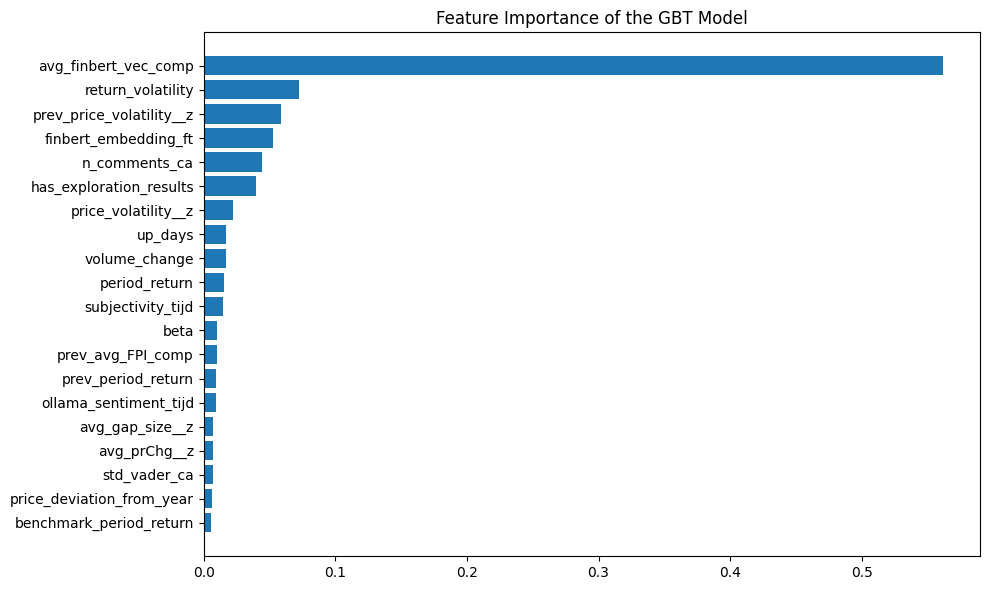

In [49]:
import pandas as pd
import numpy as np
from pyspark.sql import functions as F
from pyspark.ml.functions import vector_to_array

# --- 1) Extract importance vector (length = final feature dim) ---
gbt_stage = gbt_model.stages[-1]
imp = np.array(gbt_stage.featureImportances.toArray())

# --- 2) Get the 38 "blocks" that went into the final VectorAssembler ---
input_cols = VA_final.getInputCols()   # length ~38

# Helper: determine dimensionality contributed by a column (1 if scalar, >1 if vector)
def col_dim(df, c):
    dtype = dict(df.dtypes).get(c)
    if dtype and dtype.startswith("vector"):
        return df.select(F.size(vector_to_array(F.col(c))).alias("n")).first()["n"]
    return 1

# IMPORTANT: use a DF *after* all preprocessing stages so these columns exist.
# If gbt_predictions has them, use that:
df_for_dims = gbt_predictions

dims = [(c, col_dim(df_for_dims, c)) for c in input_cols]
total_dim = sum(d for _, d in dims)

print("Blocks:", len(input_cols))
print("Total feature dim from blocks:", total_dim)
print("GBT importance length:", len(imp))

# --- 3) Aggregate importances per block ---
rows = []
start = 0
for c, d in dims:
    end = start + d
    rows.append({
        "feature_block": c,
        "dim": int(d),
        "importance_sum": float(imp[start:end].sum()),
        "importance_mean": float(imp[start:end].mean())  # optional
    })
    start = end

imp_block_df = pd.DataFrame(rows).sort_values("importance_sum", ascending=False)

# (Optional) normalize to 1.0 total
imp_block_df["importance_sum_norm"] = imp_block_df["importance_sum"] / imp_block_df["importance_sum"].sum()

display(imp_block_df.head(20))  # in notebooks

# --- 4) Plot top-N blocks ---
import matplotlib.pyplot as plt

topn = 20
plot_df = imp_block_df.head(topn).iloc[::-1]  # reverse for horizontal bar

# plot
plt.figure(figsize=(10, 6))
plt.barh('feature_block', 'importance_sum_norm', data = plot_df)
plt.title("Feature Importance of the GBT Model")
plt.tight_layout()
plt.show()


In [50]:
important_features = imp_block_df["feature_block"].head(20)
important_features = list(important_features.values)
important_features

['avg_finbert_vec_comp',
 'return_volatility',
 'prev_price_volatility__z',
 'finbert_embedding_ft',
 'n_comments_ca',
 'has_exploration_results',
 'price_volatility__z',
 'up_days',
 'volume_change',
 'period_return',
 'subjectivity_tijd',
 'beta',
 'prev_avg_FPI_comp',
 'prev_period_return',
 'ollama_sentiment_tijd',
 'avg_gap_size__z',
 'avg_prChg__z',
 'std_vader_ca',
 'price_deviation_from_year',
 'benchmark_period_return']

### 3.5.2 Shapley values

We'll only evaluate scalars as these will give most insights in to economic signals

In [51]:
import shap
shap.plots.initjs()

In [52]:
ranges = []
start = 0
for c, d in dims:
    end = start + d
    ranges.append((c, start, end))
    start = end

In [53]:
feature_names = []

for name, s, e in ranges:
    if e - s == 1:
        feature_names.append(name)
    else:
        feature_names.extend([f"{name}[{i}]" for i in range(e - s)])

In [54]:
feature_df = (
    gbt_predictions
        .select("features")
        .withColumn("features", vector_to_array("features"))
        .select([F.col("features")[i].alias(feature_names[i])
                 for i in range(len(feature_names))])
        .toPandas()
)

explainer = shap.TreeExplainer(gbt_model.stages[-1])
sv = explainer(feature_df, check_additivity=False)

shap_values = sv.values
shap_df = pd.DataFrame(shap_values, columns=feature_df.columns)

In [55]:
shap_df

,n_comments_ca,avg_vader_ca,std_vader_ca,avg_roberta_ca,n_artices_comp,avg_polarity_title_comp,avg_polarity_content_comp,avg_subjectivity_title_comp,avg_subjectivity_content_comp,avg_ollama_comp,...,current_financing_announcement,prev_financing_announcement,second_prev_financing_announcement,third_prev_financing_announcement,return_change,volatility_change,volume_change,ft_coverage,tijd_coverage,finbert_missing
0,-0.095576,-0.004443,-0.008780,0.000247,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,-0.039752,0.0,0.0,0.0
1,-0.060906,-0.001953,-0.017827,-0.000720,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,-0.048271,0.0,0.0,0.0
2,-0.085242,-0.004443,-0.017915,-0.003644,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.079139,0.0,0.0,0.0
3,-0.055309,-0.001953,-0.006862,0.001249,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,-0.043643,0.0,0.0,0.0
4,0.034108,-0.001953,-0.008780,0.000247,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,-0.048595,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
245,-0.081621,-0.001953,-0.014644,0.001249,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.099328,0.0,0.0,0.0
246,-0.055115,-0.001892,-0.020207,0.001249,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,-0.039899,0.0,0.0,0.0
247,-0.136725,-0.001953,-0.014644,-0.001288,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,-0.042483,0.0,0.0,0.0
248,-0.147895,-0.001953,-0.014644,0.000247,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,-0.042483,0.0,0.0,0.0


In [56]:
sv_mat = sv.values if hasattr(sv, "values") else sv
if sv_mat.ndim == 3:
    sv_mat = sv_mat[:, :, 1]   # positive class
shap_values = sv_mat

In [57]:
rows = {}

for name, s, e in ranges:
    d = e - s
    block = shap_values[:, s:e]  # shape (n_obs, d)

    if d == 1:
        # scalar: keep as-is (directional)
        rows[name] = block[:, 0]
    else:
        # vector: collapse into one signed contribution per obs
        rows[name] = block.sum(axis=1)

effect_df_signed = pd.DataFrame(rows)

In [58]:
effect_df_signed.head()

,n_comments_ca,avg_vader_ca,std_vader_ca,avg_roberta_ca,n_artices_comp,avg_polarity_title_comp,avg_polarity_content_comp,avg_subjectivity_title_comp,avg_subjectivity_content_comp,avg_ollama_comp,...,current_financing_announcement,prev_financing_announcement,second_prev_financing_announcement,third_prev_financing_announcement,return_change,volatility_change,volume_change,ft_coverage,tijd_coverage,finbert_missing
0,-0.095576,-0.004443,-0.008780,0.000247,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,-0.039752,0.0,0.0,0.0
1,-0.060906,-0.001953,-0.017827,-0.000720,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,-0.048271,0.0,0.0,0.0
2,-0.085242,-0.004443,-0.017915,-0.003644,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.079139,0.0,0.0,0.0
3,-0.055309,-0.001953,-0.006862,0.001249,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,-0.043643,0.0,0.0,0.0
4,0.034108,-0.001953,-0.008780,0.000247,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,-0.048595,0.0,0.0,0.0


In [59]:
rows_abs = {}

for name, s, e in ranges:
    block = shap_values[:, s:e]
    d = e - s

    if d == 1:
        rows_abs[name] = np.abs(block[:, 0])
    else:
        # collapse vector into one magnitude per obs (recommended)
        rows_abs[name] = np.sum(np.abs(block), axis=1)

effect_df_abs = pd.DataFrame(rows_abs)

In [60]:
effect_df_abs.head()

,n_comments_ca,avg_vader_ca,std_vader_ca,avg_roberta_ca,n_artices_comp,avg_polarity_title_comp,avg_polarity_content_comp,avg_subjectivity_title_comp,avg_subjectivity_content_comp,avg_ollama_comp,...,current_financing_announcement,prev_financing_announcement,second_prev_financing_announcement,third_prev_financing_announcement,return_change,volatility_change,volume_change,ft_coverage,tijd_coverage,finbert_missing
0,0.095576,0.004443,0.008780,0.000247,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.039752,0.0,0.0,0.0
1,0.060906,0.001953,0.017827,0.000720,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.048271,0.0,0.0,0.0
2,0.085242,0.004443,0.017915,0.003644,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.079139,0.0,0.0,0.0
3,0.055309,0.001953,0.006862,0.001249,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.043643,0.0,0.0,0.0
4,0.034108,0.001953,0.008780,0.000247,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.048595,0.0,0.0,0.0


In [61]:
scalar_cols = []
scalar_idx  = []

for name, s, e in ranges:
    if e - s == 1:
        scalar_cols.append(name)
        scalar_idx.append(s)

shap_scalar_df = pd.DataFrame(
    shap_values[:, scalar_idx],
    columns=scalar_cols
)

In [62]:
scalar_cols

['n_comments_ca',
 'avg_vader_ca',
 'std_vader_ca',
 'avg_roberta_ca',
 'n_artices_comp',
 'avg_polarity_title_comp',
 'avg_polarity_content_comp',
 'avg_subjectivity_title_comp',
 'avg_subjectivity_content_comp',
 'avg_ollama_comp',
 'std_ollama_comp',
 'avg_FPI_comp',
 'std_FPI_comp',
 'accum_FPI_comp',
 'std_avg_FPI_last3_comp',
 'prev_std_FPI_comp',
 'prev_avg_FPI_comp',
 'article_count_ft',
 'avg_words_ft',
 'polarity_ft',
 'subjectivity_ft',
 'ollama_sentiment_ft',
 'article_count_tijd',
 'avg_words_tijd',
 'polarity_tijd',
 'subjectivity_tijd',
 'ollama_sentiment_tijd',
 'avg_close__z',
 'price_volatility__z',
 'avg_daily_volume__z',
 'volume_volatility__z',
 'avg_gap_size__z',
 'max_gap__z',
 'avg_prChg__z',
 'prev_price_volatility__z',
 'prev_volume_volatility__z',
 'period_return',
 'benchmark_period_return',
 'beta',
 'return_volatility',
 'gap_count',
 'up_days',
 'down_days',
 'has_property_acquisition',
 'has_exploration_results',
 'price_deviation_from_year',
 'has_finan

In [63]:
i = 0
row = effect_df_abs.iloc[i].sort_values(ascending=False)
print(row.head(5))

avg_finbert_vec_comp       2.623943
finbert_embedding_ft       0.202312
n_comments_ca              0.095576
return_volatility          0.089663
has_exploration_results    0.062195
Name: 0, dtype: float64


#### Violin Plot

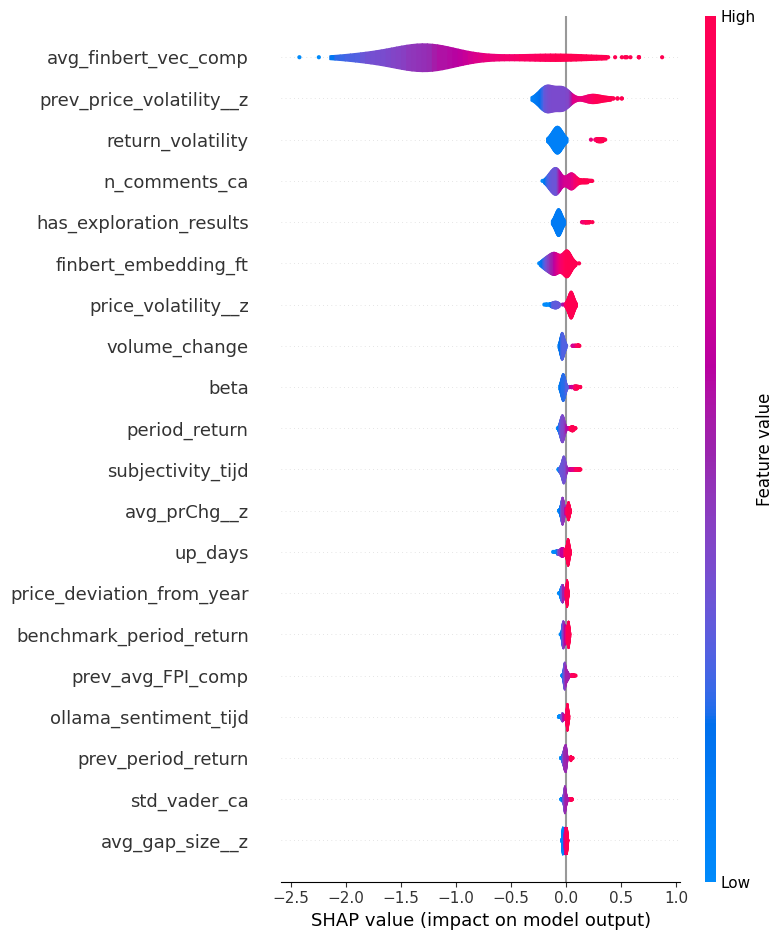

In [64]:
shap.summary_plot(
    effect_df_signed.values,
    effect_df_signed,
    plot_type="violin",
    max_display=20
)

#### Global bar plot

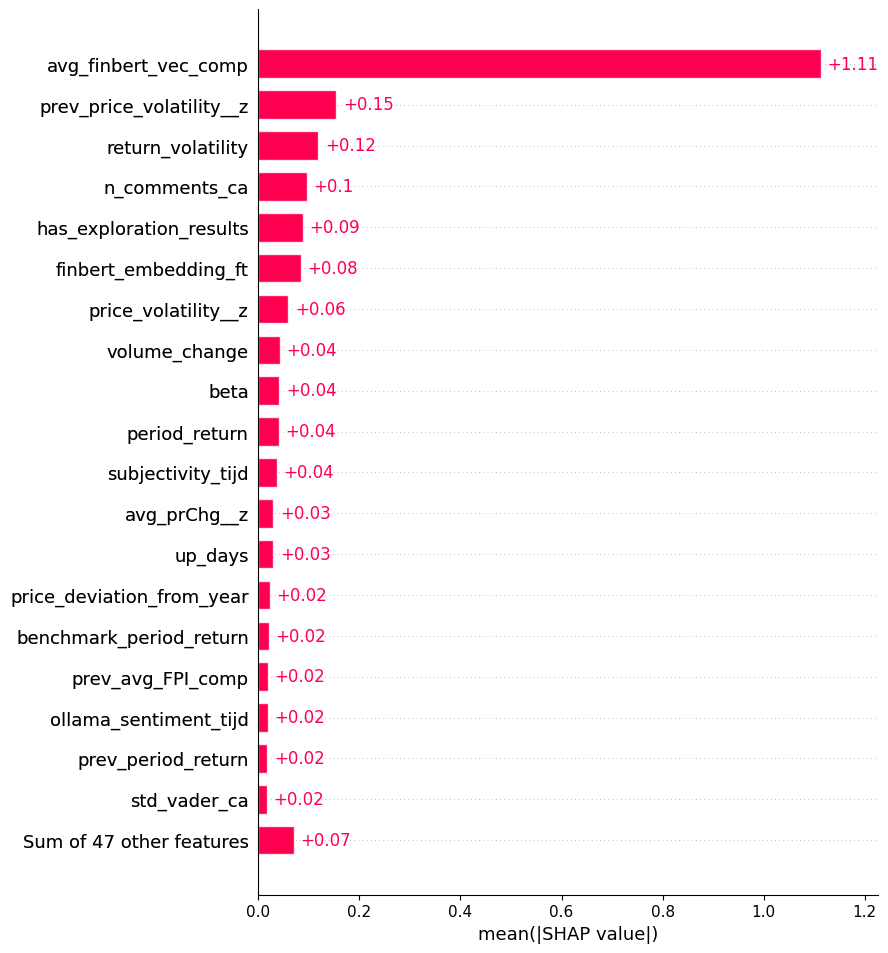

In [65]:
shap_exp = shap.Explanation(
    values=effect_df_signed.values,
    feature_names=effect_df_signed.columns
)

shap.plots.bar(shap_exp.abs.mean(0), max_display=20)

#### Waterfall Plot

In [66]:
i = 1

In [67]:
contrib = effect_df_signed.loc[i].copy()
contrib = contrib.sort_values(key=lambda s: np.abs(s), ascending=False)  # biggest impacts first
contrib = contrib.head(20) 

In [68]:
import numpy as np
import matplotlib.pyplot as plt

def waterfall_from_contrib(
    contrib: pd.Series,
    base=0.0,
    title="Block-level SHAP Waterfall"
):
    # contrib: Series(index=feature_name, values=signed contribution)
    names = contrib.index.tolist()
    vals  = contrib.values.astype(float)

    # cumulative positions
    cum = np.cumsum(np.r_[base, vals])
    starts = cum[:-1]
    widths = vals

    # color rule: red = positive, blue = negative
    colors = ["#d62728" if v > 0 else "#1f77b4" for v in vals]

    plt.figure(figsize=(10, 6))

    for k, (name, w, s, c) in enumerate(zip(names, widths, starts, colors)):
        plt.barh(
            y=k,
            width=w,
            left=s,
            color=c,
            edgecolor="black"
        )

    plt.axvline(base, linestyle="--", color="black", linewidth=1)
    plt.yticks(range(len(names)), names)
    plt.xlabel("Model output contribution (signed)")
    plt.title(title)
    plt.gca().invert_yaxis()
    plt.tight_layout()
    plt.show()



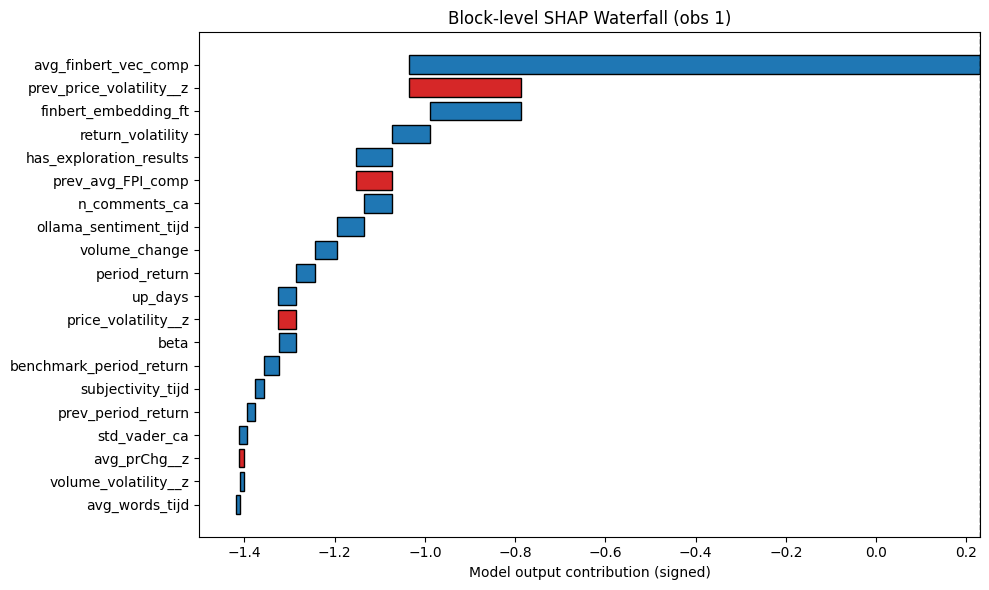

In [69]:
i = 1  # observation index

base = 0.0
if "sv" in globals():
    base = sv.base_values[i]
    if np.ndim(base):
        base = base[1]  # positive class

waterfall_from_contrib(
    contrib,
    base=base,
    title=f"Block-level SHAP Waterfall (obs {i})"
)

In [70]:
contrib

avg_finbert_vec_comp       -1.265947
prev_price_volatility__z    0.249405
finbert_embedding_ft       -0.202147
return_volatility          -0.083276
has_exploration_results    -0.080081
prev_avg_FPI_comp           0.078518
n_comments_ca              -0.060906
ollama_sentiment_tijd      -0.060018
volume_change              -0.048271
period_return              -0.042413
up_days                    -0.039529
price_volatility__z         0.038387
beta                       -0.036981
benchmark_period_return    -0.033908
subjectivity_tijd          -0.018699
prev_period_return         -0.018308
std_vader_ca               -0.017827
avg_prChg__z                0.011962
volume_volatility__z       -0.009746
avg_words_tijd             -0.008174
Name: 1, dtype: float64

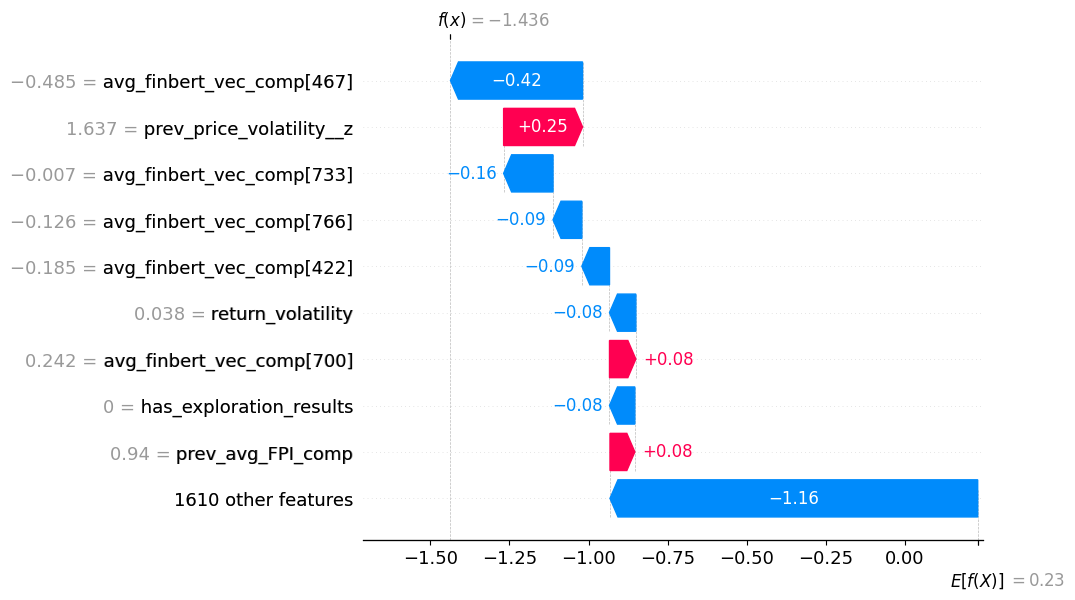

In [71]:
shap.plots.waterfall(sv[1])

#### Dependence Plot

In [72]:
cols_imp = [c for c in feature_df.columns if c in important_features]
cols_imp

['n_comments_ca',
 'std_vader_ca',
 'prev_avg_FPI_comp',
 'subjectivity_tijd',
 'ollama_sentiment_tijd',
 'price_volatility__z',
 'avg_gap_size__z',
 'avg_prChg__z',
 'prev_price_volatility__z',
 'period_return',
 'benchmark_period_return',
 'beta',
 'return_volatility',
 'up_days',
 'has_exploration_results',
 'price_deviation_from_year',
 'prev_period_return',
 'volume_change']

In [73]:
scalar_cols_imp = [c for c in scalar_cols if c in important_features]
scalar_cols_imp

['n_comments_ca',
 'std_vader_ca',
 'prev_avg_FPI_comp',
 'subjectivity_tijd',
 'ollama_sentiment_tijd',
 'price_volatility__z',
 'avg_gap_size__z',
 'avg_prChg__z',
 'prev_price_volatility__z',
 'period_return',
 'benchmark_period_return',
 'beta',
 'return_volatility',
 'up_days',
 'has_exploration_results',
 'price_deviation_from_year',
 'prev_period_return',
 'volume_change']

In [74]:
shap_exp

.values =
array([[-0.09557644, -0.00444283, -0.00877959, ...,  0.        ,
         0.        ,  0.        ],
       [-0.06090571, -0.00195303, -0.01782653, ...,  0.        ,
         0.        ,  0.        ],
       [-0.08524157, -0.00444283, -0.01791497, ...,  0.        ,
         0.        ,  0.        ],
       ...,
       [-0.13672536, -0.00195303, -0.0146441 , ...,  0.        ,
         0.        ,  0.        ],
       [-0.14789455, -0.00195303, -0.0146441 , ...,  0.        ,
         0.        ,  0.        ],
       [-0.12521116, -0.00444283, -0.02265279, ...,  0.        ,
         0.        ,  0.        ]], shape=(250, 66))

In [75]:
X =  feature_df[scalar_cols_imp]       # pandas DF
shap_vals = shap_df[scalar_cols_imp].values

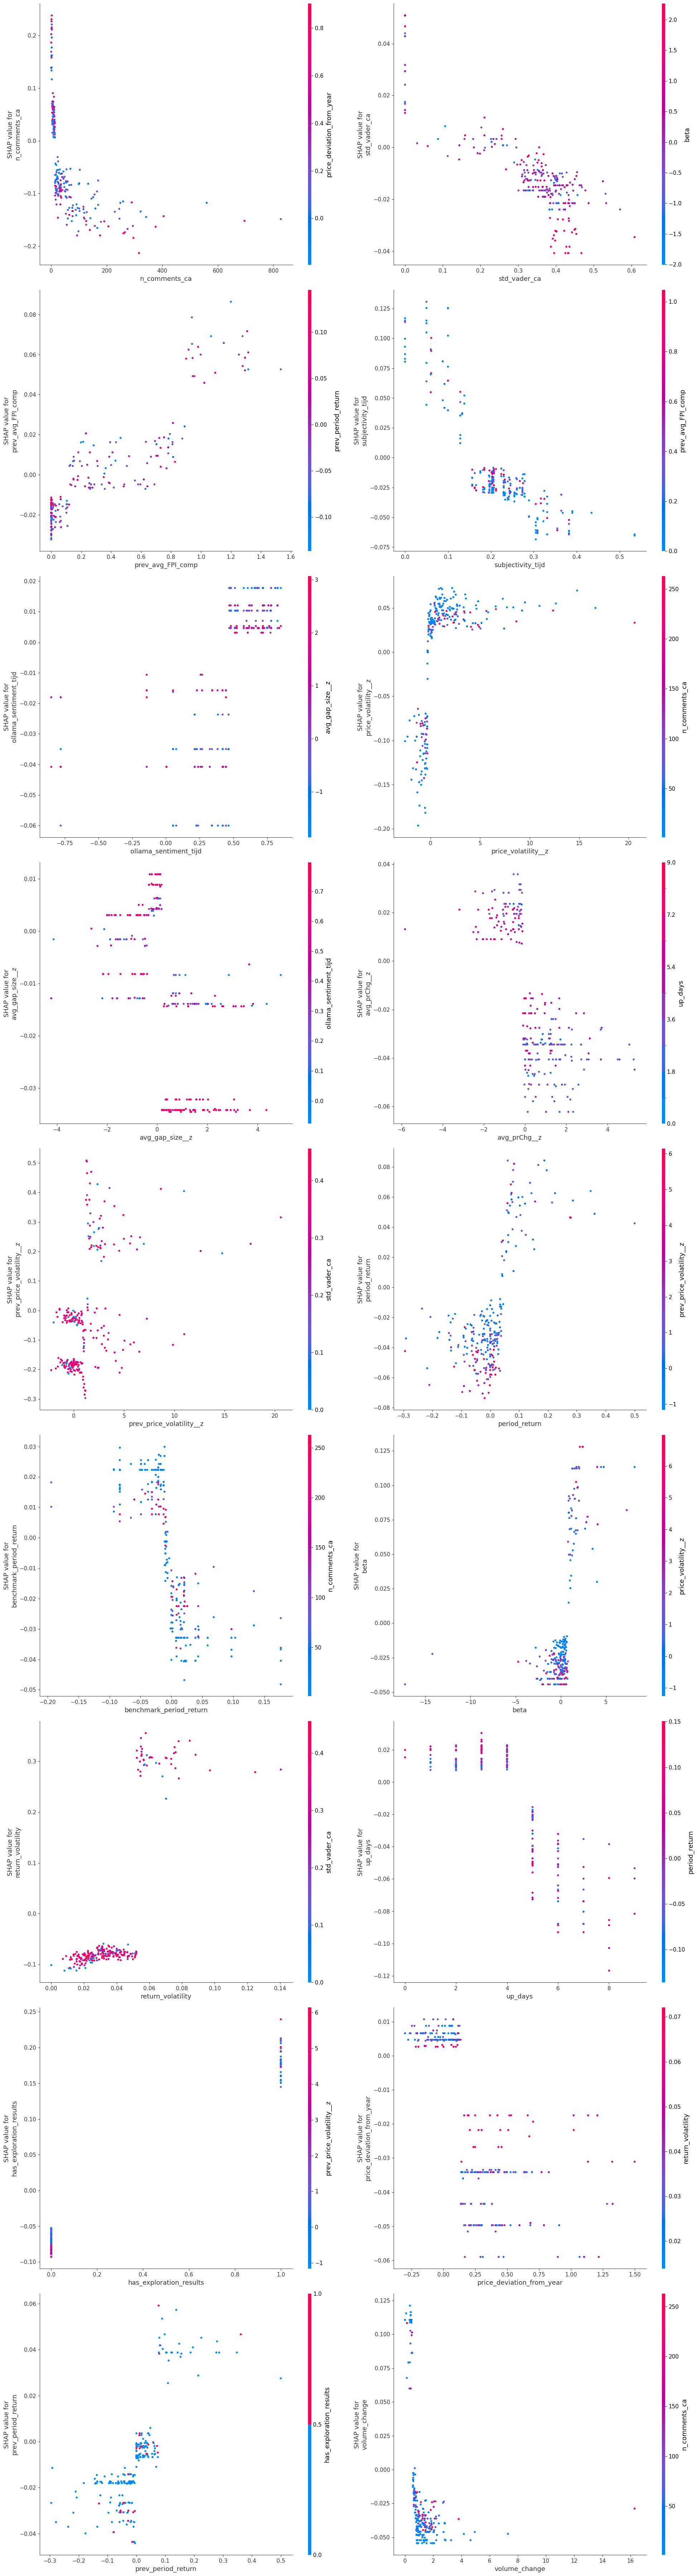

In [76]:
n = len(X.columns)
fig, axes = plt.subplots(nrows=(n + 1) // 2, ncols=2, figsize=(20, 4 * n))
axes = axes.ravel()

for i, col in enumerate(X.columns):
    shap.dependence_plot(
        col,
        shap_vals,
        X,    
        ax=axes[i],
        show=False
    )

# hide unused axes
for j in range(i + 1, len(axes)):
    axes[j].set_visible(False)

plt.tight_layout()
plt.show()

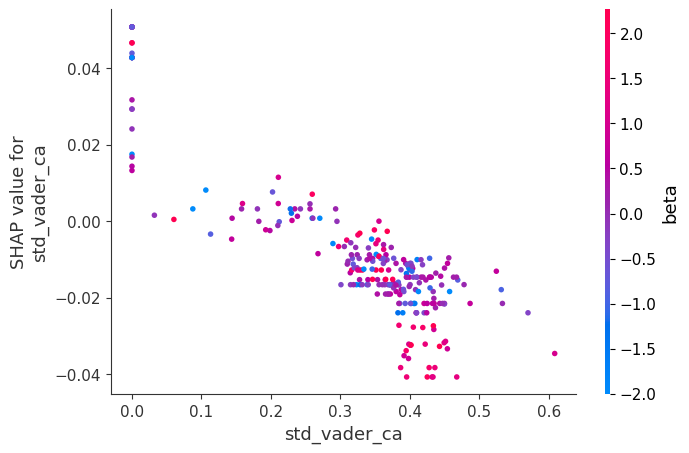

In [77]:
shap.dependence_plot(
    "std_vader_ca",
    shap_vals,
    X,
    interaction_index="beta",
    show=True
)

In [81]:
feature_names = X.columns.tolist()
feature_names.index("std_vader_ca")

k = X.columns.get_loc("std_vader_ca")
shap_std_vader_ca = shap_vals[:, k]

In [82]:
df_plot = X.copy()
df_plot["shap_std_vader_ca"] = shap_std_vader_ca

In [83]:
df_plot.head()

,n_comments_ca,std_vader_ca,prev_avg_FPI_comp,subjectivity_tijd,ollama_sentiment_tijd,price_volatility__z,avg_gap_size__z,avg_prChg__z,prev_price_volatility__z,period_return,benchmark_period_return,beta,return_volatility,up_days,has_exploration_results,price_deviation_from_year,prev_period_return,volume_change,shap_std_vader_ca
0,49.0,0.365682,0.689583,0.195315,0.225848,1.606430,-1.521842,-2.027941,0.488343,-0.020513,0.044059,0.533749,0.012550,5.0,0.0,0.126197,-0.015707,1.342111,-0.008780
1,28.0,0.390806,0.939924,0.206216,0.239204,0.434187,-0.327397,-0.496314,1.637073,-0.063953,0.007515,-0.678860,0.038139,5.0,0.0,-0.022548,-0.020513,1.224402,-0.017827
2,30.0,0.387577,0.940967,0.201515,0.325351,-0.684772,-0.512981,-0.129326,0.473043,0.005714,-0.007346,0.652032,0.009128,6.0,0.0,0.013601,-0.063953,0.239746,-0.017915
3,24.0,0.322065,0.956737,0.274713,0.422041,-1.643880,-0.142377,-0.147787,-0.638076,0.005780,-0.025143,-0.003626,0.007121,3.0,0.0,0.007483,0.005714,1.771550,-0.006862
4,8.0,0.315889,0.944955,0.232192,0.229893,0.772386,1.054178,1.360144,-1.590464,-0.022099,0.009020,0.124526,0.020193,3.0,0.0,0.060495,0.005780,0.996058,-0.008780


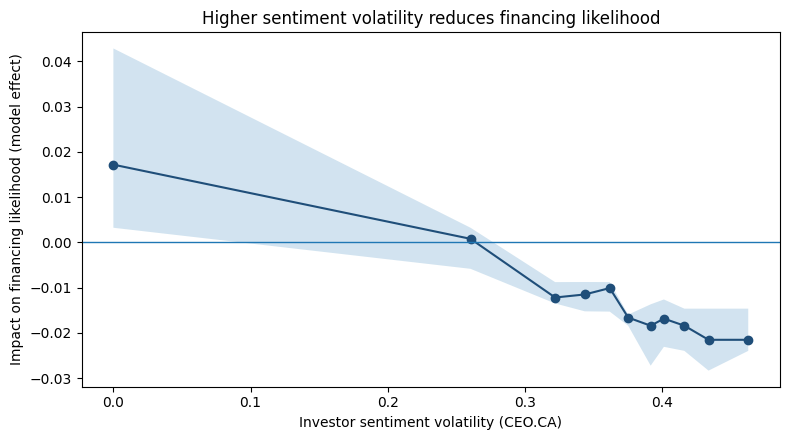

In [88]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# df needs: std_vader_ca, shap_std_vader_ca
tmp = df_plot[['std_vader_ca', 'shap_std_vader_ca']].dropna().copy()

# quantile bins (more stable than equal-width)
tmp['bin'] = pd.qcut(tmp['std_vader_ca'], q=12, duplicates='drop')

g = tmp.groupby('bin').agg(
    x=('std_vader_ca', 'median'),
    y=('shap_std_vader_ca', 'median'),
    n=('shap_std_vader_ca', 'size'),
    y_lo=('shap_std_vader_ca', lambda s: np.quantile(s, 0.25)),
    y_hi=('shap_std_vader_ca', lambda s: np.quantile(s, 0.75)),
).sort_values('x')

plt.figure(figsize=(8,4.5))
plt.plot(g['x'], g['y'], marker='o', color="#1f4e79")
plt.fill_between(g['x'], g['y_lo'], g['y_hi'], alpha=0.2)

plt.axhline(0, linewidth=1)
plt.xlabel("Investor sentiment volatility (CEO.CA)")
plt.ylabel("Impact on financing likelihood (model effect)")
plt.title("Higher sentiment volatility reduces financing likelihood")
plt.tight_layout()
plt.show()

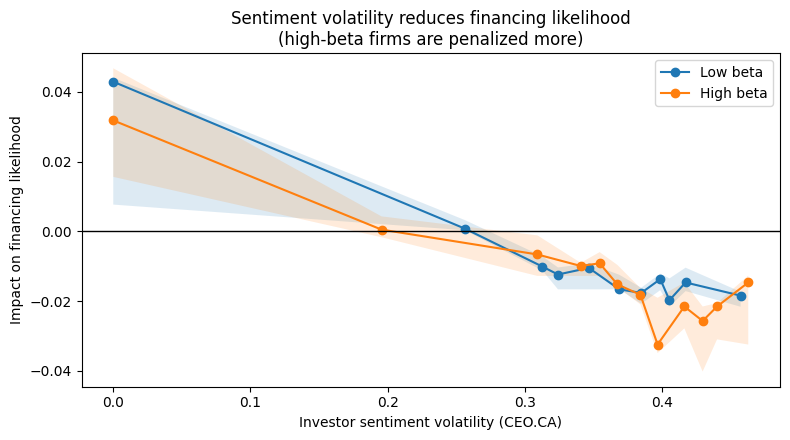

In [85]:
df_plot["beta_group"] = np.where(
    df_plot["beta"] >= df_plot["beta"].median(),
    "High beta",
    "Low beta"
)

def binned_curve(df, x, y, q=12):
    d = df.copy()
    d["bin"] = pd.qcut(d[x], q=q, duplicates="drop")
    g = d.groupby("bin").agg(
        x=("std_vader_ca", "median"),
        y=("shap_std_vader_ca", "median"),
        lo=("shap_std_vader_ca", lambda s: s.quantile(0.25)),
        hi=("shap_std_vader_ca", lambda s: s.quantile(0.75)),
    ).sort_values("x")
    return g

g_hi = binned_curve(df_plot[df_plot["beta_group"]=="High beta"],
                    "std_vader_ca","shap_std_vader_ca")
g_lo = binned_curve(df_plot[df_plot["beta_group"]=="Low beta"],
                    "std_vader_ca","shap_std_vader_ca")

plt.figure(figsize=(8,4.5))

plt.plot(g_lo["x"], g_lo["y"], marker="o", label="Low beta")
plt.fill_between(g_lo["x"], g_lo["lo"], g_lo["hi"], alpha=0.15)

plt.plot(g_hi["x"], g_hi["y"], marker="o", label="High beta")
plt.fill_between(g_hi["x"], g_hi["lo"], g_hi["hi"], alpha=0.15)

plt.axhline(0, lw=1, color="black")
plt.xlabel("Investor sentiment volatility (CEO.CA)")
plt.ylabel("Impact on financing likelihood")
plt.title("Sentiment volatility reduces financing likelihood\n(high-beta firms are penalized more)")
plt.legend()
plt.tight_layout()
plt.show()


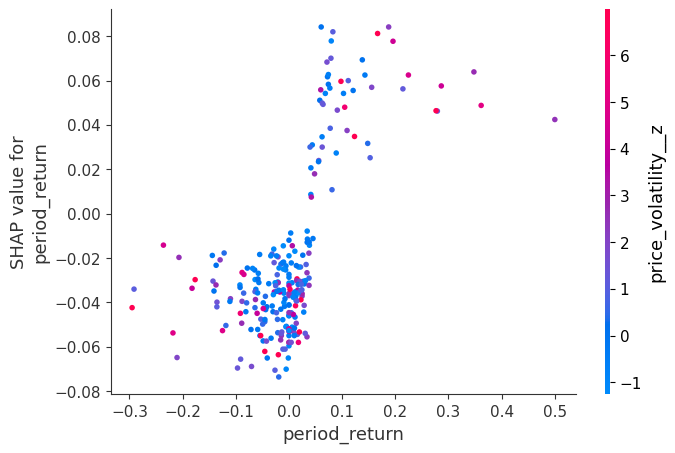

In [ ]:
shap.dependence_plot(
    "period_return",
    shap_vals,
    X,
    interaction_index="price_volatility__z",
    show=True
)

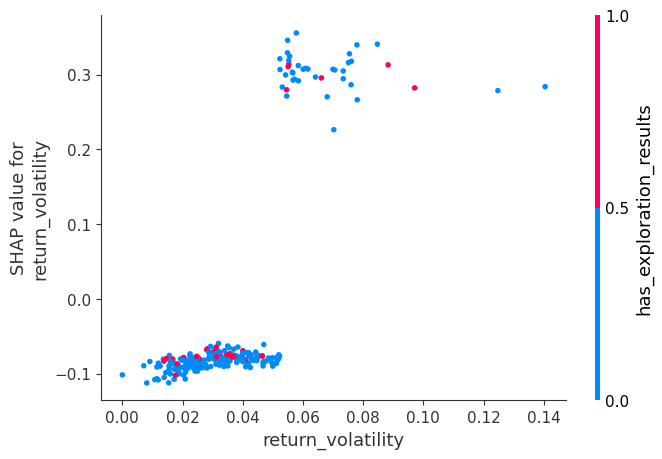

In [ ]:
shap.dependence_plot(
    "return_volatility",
    shap_vals,
    X,
    interaction_index="has_exploration_results",
    show=True
)

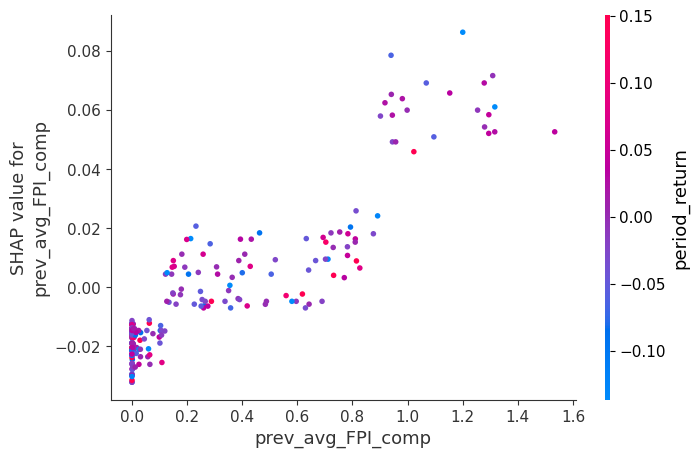

In [ ]:
shap.dependence_plot(
    "prev_avg_FPI_comp",
    shap_vals,
    X,
    interaction_index="period_return",
    show=True
)

In [ ]:
X

,n_comments_ca,std_vader_ca,prev_avg_FPI_comp,subjectivity_tijd,ollama_sentiment_tijd,price_volatility__z,avg_gap_size__z,avg_prChg__z,prev_price_volatility__z,period_return,benchmark_period_return,beta,return_volatility,up_days,has_exploration_results,price_deviation_from_year,prev_period_return,volume_change
0,49.0,0.365682,0.689583,0.195315,0.225848,1.606430,-1.521842,-2.027941,0.488343,-0.020513,0.044059,0.533749,0.012550,5.0,0.0,0.126197,-0.015707,1.342111
1,28.0,0.390806,0.939924,0.206216,0.239204,0.434187,-0.327397,-0.496314,1.637073,-0.063953,0.007515,-0.678860,0.038139,5.0,0.0,-0.022548,-0.020513,1.224402
2,30.0,0.387577,0.940967,0.201515,0.325351,-0.684772,-0.512981,-0.129326,0.473043,0.005714,-0.007346,0.652032,0.009128,6.0,0.0,0.013601,-0.063953,0.239746
3,24.0,0.322065,0.956737,0.274713,0.422041,-1.643880,-0.142377,-0.147787,-0.638076,0.005780,-0.025143,-0.003626,0.007121,3.0,0.0,0.007483,0.005714,1.771550
4,8.0,0.315889,0.944955,0.232192,0.229893,0.772386,1.054178,1.360144,-1.590464,-0.022099,0.009020,0.124526,0.020193,3.0,0.0,0.060495,0.005780,0.996058
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
245,133.0,0.409856,0.102726,0.205744,0.636246,-1.024254,0.881429,0.365851,-0.377863,-0.092258,0.016246,-0.436120,0.011970,2.0,0.0,-0.025225,-0.062300,0.473481
246,103.0,0.434618,0.105604,0.229873,0.606678,-1.400644,0.262426,0.158164,-1.046293,-0.029383,0.014892,0.207274,0.016742,3.0,1.0,0.048031,-0.092258,0.927642
247,119.0,0.462864,0.054064,0.184676,0.213719,-0.409776,0.079759,0.281812,-1.420994,-0.038052,-0.083378,0.221898,0.022400,5.0,0.0,0.046329,-0.029383,0.882458
248,246.0,0.405111,0.060005,0.308394,0.779055,4.080912,2.257710,1.497562,-0.434574,-0.182285,0.011622,-0.313829,0.031781,2.0,0.0,0.214457,-0.038052,1.472358


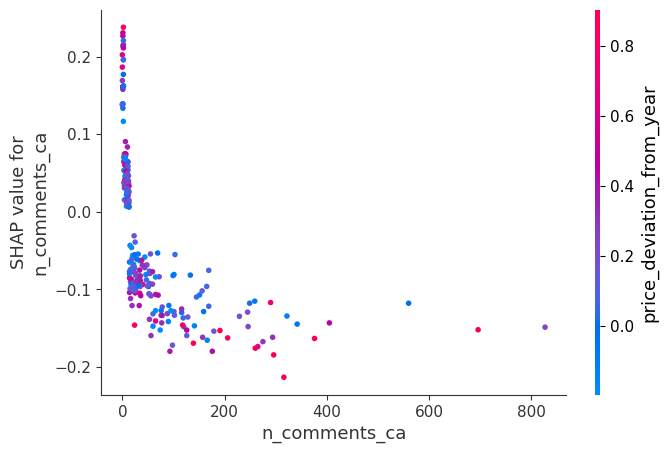

In [ ]:
shap.dependence_plot(
    "n_comments_ca",
    shap_vals,
    X,
    interaction_index="price_deviation_from_year",
    show=True
)